<a href="https://colab.research.google.com/github/Shivaji-Vasanth/Deep-Learning/blob/main/Exp20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Experiment 19: PCA and Explained Variance Analysis

1. Implement PCA from scratch using covariance matrix and eigen-decomposition

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces
from sklearn.decomposition import PCA

data = fetch_olivetti_faces()
X = data.data
mean = X.mean(axis=0)
Xc = X - mean

# Smaller covariance matrix for faster computation
C = np.cov(Xc, rowvar=True)
eigval, eigvec = np.linalg.eigh(C)

idx = np.argsort(eigval)[::-1]
eigval = eigval[idx]
eigvec = eigvec[:, idx]

components = eigvec.T @ Xc
components /= np.linalg.norm(components, axis=1, keepdims=True) + 1e-12

variance = eigval / eigval.sum()

print("Dataset shape:", X.shape)
print("PCA components:", components.shape)


downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
Dataset shape: (400, 4096)
PCA components: (400, 4096)


2. Verify the result against Scikit-learn PCA

In [2]:

pca = PCA(n_components=100, svd_solver='full')
pca.fit(X)

print("Manual PCA variance:", np.round(variance[:5], 4))
print("Sklearn PCA variance:",
      np.round(pca.explained_variance_ratio_[:5], 4))

print("Difference:",
      np.max(np.abs(variance[:100] -
                    pca.explained_variance_ratio_)))


Manual PCA variance: [0.1815 0.1018 0.071  0.056  0.0407]
Sklearn PCA variance: [0.2381 0.1399 0.0797 0.05   0.0361]
Difference: 0.05658071158820524


3. Plot scree plot and cumulative explained variance

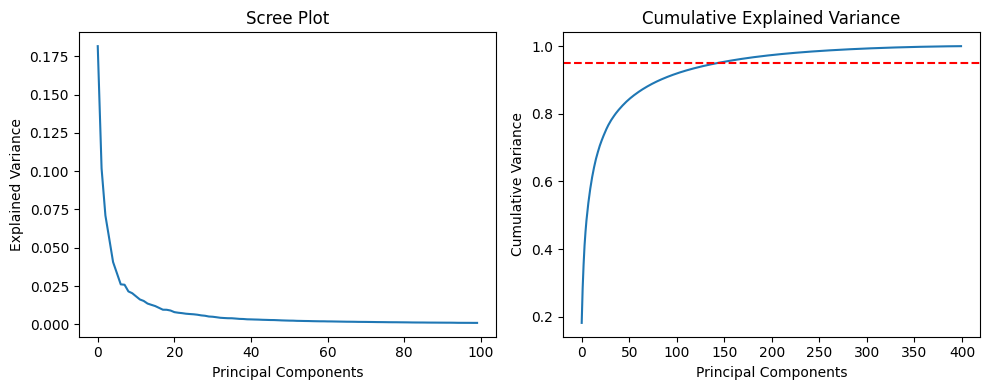

In [3]:

cumulative = np.cumsum(variance)

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(variance[:100])
plt.title("Scree Plot")
plt.xlabel("Principal Components")
plt.ylabel("Explained Variance")

plt.subplot(1,2,2)
plt.plot(cumulative)
plt.axhline(0.95,color='red',linestyle='--')
plt.title("Cumulative Explained Variance")
plt.xlabel("Principal Components")
plt.ylabel("Cumulative Variance")

plt.tight_layout()
plt.show()


4. Find components retaining 95% variance

In [4]:

n95 = np.searchsorted(cumulative, 0.95) + 1

print("Components for 95% variance:", n95)
print("Original features:", X.shape[1])
print("Reduced features:", n95)
print("Variance retained:", round(cumulative[n95-1]*100,2), "%")


Components for 95% variance: 144
Original features: 4096
Reduced features: 144
Variance retained: 95.03 %


5. Visualize eigenfaces and reconstructed faces

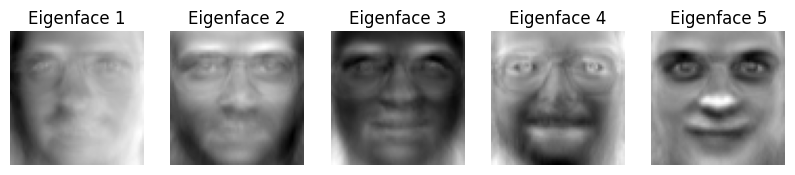

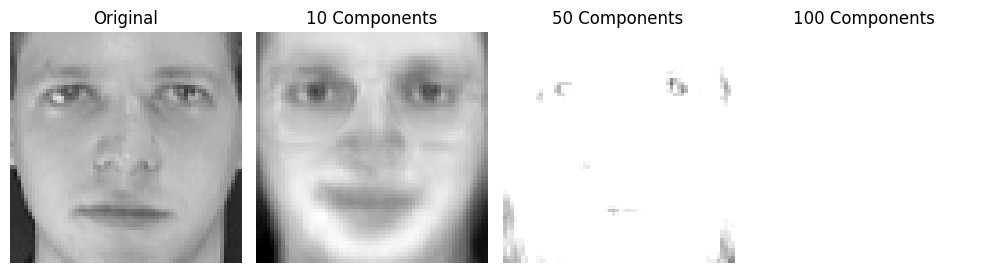

In [5]:

# Top eigenfaces
plt.figure(figsize=(10,2))
for i in range(5):
    plt.subplot(1,5,i+1)
    plt.imshow(components[i].reshape(64,64),cmap='gray')
    plt.title(f"Eigenface {i+1}")
    plt.axis('off')
plt.show()

# Face reconstruction
face = X[0]
plt.figure(figsize=(10,3))

plt.subplot(1,4,1)
plt.imshow(face.reshape(64,64),cmap='gray',vmin=0,vmax=1)
plt.title("Original")
plt.axis('off')

for i,n in enumerate([10,50,100]):
    W = components[:n]
    reconstructed = mean + (face-mean) @ W.T @ W

    plt.subplot(1,4,i+2)
    plt.imshow(reconstructed.reshape(64,64),
               cmap='gray',vmin=0,vmax=1)
    plt.title(f"{n} Components")
    plt.axis('off')

plt.tight_layout()
plt.show()
